# Graphicalizing a Scene Image

This notebook loads a local village landscape with houses, cars, and people, asks a vision-language model to describe the scene and locate foreground entities, analyzes saved region crops against the visual ontology, and extracts relations across the resulting graph. Install the optional dependency with `pip install -e '.[image]'`. Set `OPENAI_API_KEY` in the environment before running the model cell; the key is read by the OpenAI SDK and is never stored in this notebook.

Image: complex_landscape_test.png


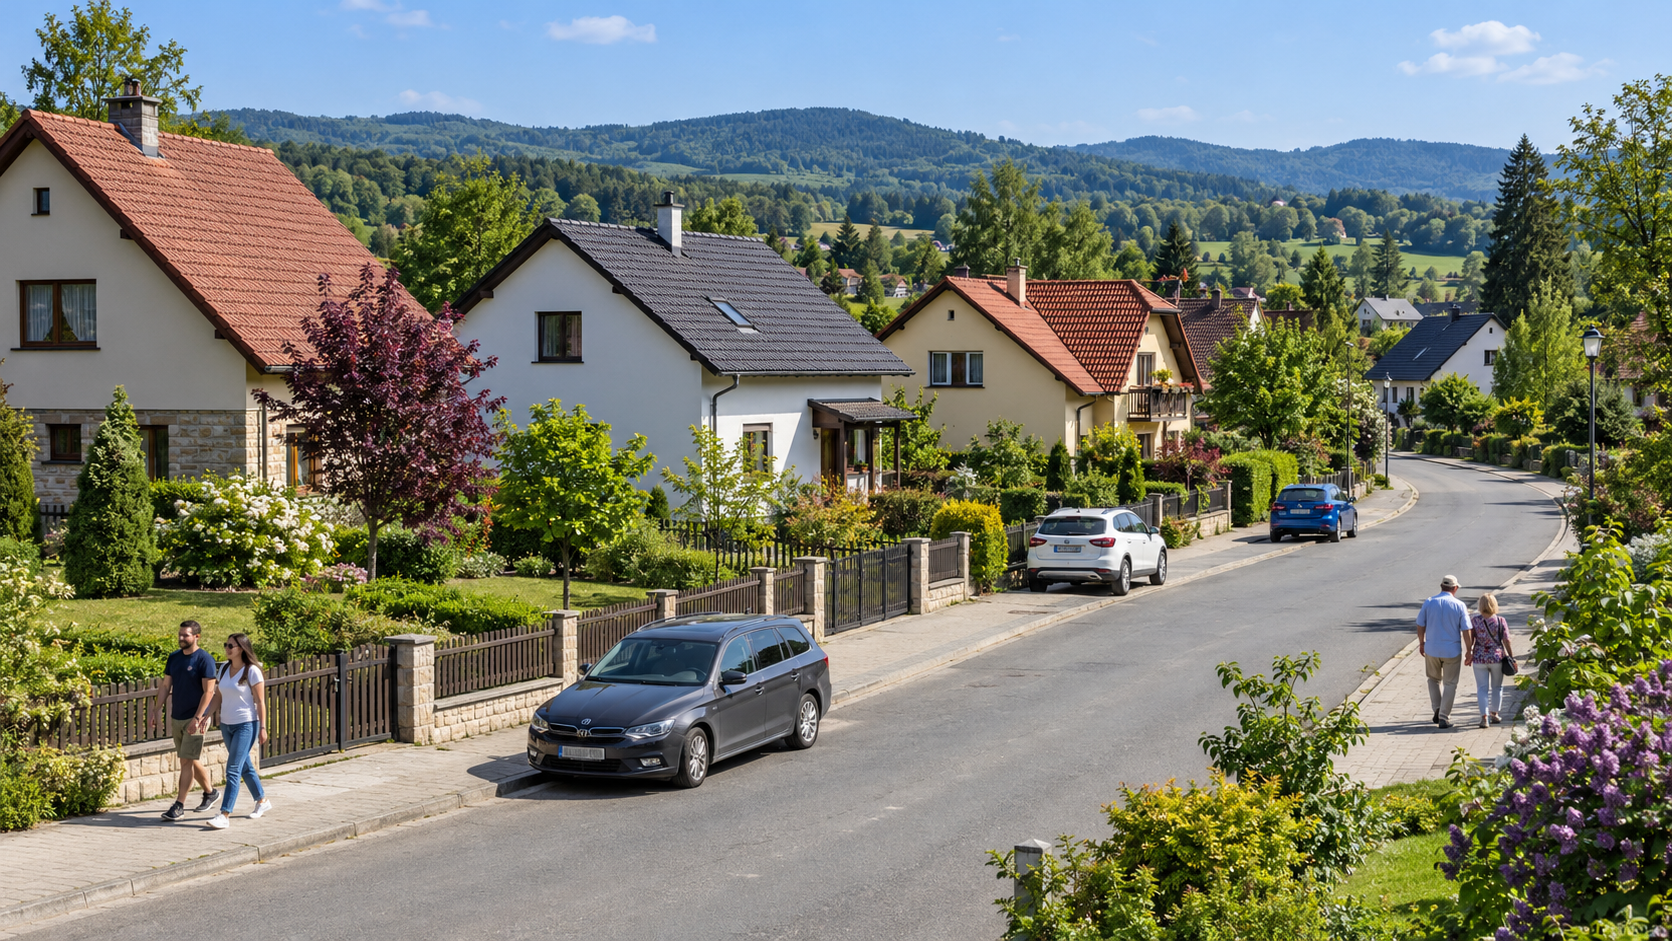

In [1]:
%config InlineBackend.figure_format = 'retina'

%load_ext autoreload
%autoreload 2

from pathlib import Path
from IPython.display import Image as DisplayImage, display

from semantic_graphicalizer import ImageGraphicalizer, display_graph

ROOT = Path.cwd()
while not (ROOT / 'pyproject.toml').is_file() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
IMAGE_ROOT = ROOT / 'domains' / 'image'

image_path = IMAGE_ROOT / 'data' / 'raw' / 'complex_landscape_test.png'
if not image_path.is_file():
    raise FileNotFoundError(f'Add a local photograph at {image_path}')

print(f'Image: {image_path.name}')
display(DisplayImage(filename=str(image_path), width=900))

## OpenAI vision model

The image workflow defaults to `gpt-5.6-terra` through the Responses API. The workflow has three image-specific stages: whole-image scene inventory, per-crop ontology analysis, and document-level relation extraction. Region crops are saved under `domains/image/data/processed/regions/`.

In [ ]:
graphicalizer = ImageGraphicalizer(
    ontology=IMAGE_ROOT / 'configs' / 'ontologies' / 'visual.yaml',
    prompts=IMAGE_ROOT / 'configs' / 'prompts' / 'scene_analysis.yaml',
    crop_dir=IMAGE_ROOT / 'data' / 'processed' / 'regions',
    verbose=True,
)

graphs = graphicalizer.transform(image_path)
graph = graphs[0]
print(f"ID: {graph.graph['document_id']}")
print(f"Scene: {graph.graph['scene_summary']}")
print(f"Regions: {len(graph.graph['parts'])} | Nodes: {graph.number_of_nodes()} | Edges: {graph.number_of_edges()}")

In [ ]:
relation_nodes = [
    (node_id, data)
    for node_id, data in graph.nodes(data=True)
    if data.get('relation') is not None
]

print('Entities:')
for node_id, data in graph.nodes(data=True):
    if data.get('relation') is None:
        attributes = data.get('attributes', {})
        description = attributes.get('description', '')
        print(f"- {node_id}: {data['type']} — {description}")

print('\nRelations:')
for relation_id, data in relation_nodes:
    arguments = ', '.join(
        f"{edge.get('role')}={target}"
        for _source, target, edge in graph.out_edges(relation_id, data=True)
    )
    print(f"- {data['type']}[{data['relation']}]({arguments})")

print('\nGraph:')
display(display_graph(graph, mode='text'))

## Overlay the graph on the image

Entity nodes are anchored at the centers of their detected bounding boxes. Reified relation nodes are placed at the center of their argument entities, with argument edges drawn over the image. Whole-scene nodes and relations involving them are hidden by default to reduce clutter; pass `show_scene_nodes=True` to include them.

In [ ]:
display(graphicalizer.display_on_image(graph, image=image_path))

In [ ]:
display_graph(
    graph,
    mode='dynamic',
    layout='force',
    show_derived_links=False,
    show_source=True,
    max_width=34,
    width=1200,
    height=760,
    charge_strength=-10,
    link_distance=150,
    component_spacing=100,
    component_strength=0.3,
    parallel_edge_spacing=320,
)

## Inspect region crops and provenance

Each part records its source image, normalized bounding box, pixel bounding box, and saved crop path. Invalid or zero-area boxes are skipped and reported in `graph.graph['warnings']`.

In [ ]:
for part in graph.graph['parts']:
    print(part['part_id'])
    print(f"Box: {part['source_locator']['normalized_bbox']} (normalized)")
    print(f"Pixels: {part['source_locator']['pixel_bbox']}")
    print(f"Crop: {part['metadata']['crop_path']}")
    display(DisplayImage(filename=part['metadata']['crop_path'], width=360))

graph.graph['warnings']